# 學生學習與作業版｜任務 5：分組統計與比較

**姓名：** 王翊綺　**學號／組別：** C114118117　**完成日期：** 11/18

**學習目標：** 以分組筆數、平均數與中位數比較類別，避免直接推論因果。

本單元與教師版「任務 5」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「5.1 分組」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [33]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 5.1 用 groupby 分組
**觀念說明：**平均數必須與人數一起看；`count` 是非缺失數，`size` 是列數。本例科系隨機分配，沒有直接納入生成成績的公式。


## 💻 學生作業 05-P1｜Vibe Coding 程式填空
**對應教師版：**任務 5「5.1 分組」的示範程式。

**任務：**按 department 分組，彙總 quiz_score 的 count、mean、median，存成 summary。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：按 department 分組，彙總 quiz_score 的 count、mean、median，存成 summary。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


In [4]:
# 以科系分組，聚合成績的有效筆數、平均與中位數
summary = df.groupby("department",as_index=False)["quiz_score"].agg(["count", "mean", "median"])
display(summary)  # TODO：按科系分組，計算成績 count、mean、median
display(summary)
print("各組有效人數加總：", summary["count"].sum())
print("資料總人數：", len(df))
assert summary["count"].sum() == df["quiz_score"].count()


,department,count,mean,median
0,企業管理,21,80.666667,81.0
1,資訊管理,15,79.733333,80.0
2,金融管理,24,76.583333,76.5


,department,count,mean,median
0,企業管理,21,80.666667,81.0
1,資訊管理,15,79.733333,80.0
2,金融管理,24,76.583333,76.5


各組有效人數加總： 60
資料總人數： 60


### ✅ 作業 05-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [3]:
assert list(summary.columns) == ["count", "mean", "median"]
assert summary["count"].sum() == df["quiz_score"].count()
print("檢查通過：統計欄位與有效人數正確。")


檢查通過：統計欄位與有效人數正確。


### ✍️ 作業 05-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：前後程式+我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：按 department 分組，彙總 quiz_score 的 count、mean、median，存成 summary。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。

- 我補上的程式在做什麼：以deparment當索引，抓出各科系的分數，計算人數個數、平均值及中位數。

- 執行或驗證遇到的問題與修正：輸出時department項目標題和其他欄位沒對齊，原因是程式將department當作分組欄列中的標籤，加上as_index=False，讓它被認定為普通欄位。

- 檢查結果及我如何確認：使用AI提供的程式做驗證。(如下)

① 確認原 df 未被修改（把第 1 行放在 summary = 那行之前）：


In [10]:
df_before = df.copy(deep=True)
#... 執行上面的 summary 程式 ...
print("df 是否未被修改：", df.equals(df_before))   # 期望印出 True

df 是否未被修改： True


② 抽一組手動重算，對照 summary 的數字（換其他科系名即可）：

In [18]:
dept = "資訊管理"
sub = df.loc[df["department"] == dept, "quiz_score"]
summary = summary.set_index("department")
print("手動算：", sub.count(), sub.mean(), sub.median())
print("summary 對應列：")
print(summary.loc[dept])          # 三個數字應與上面完全一致

手動算： 15 79.73333333333333 80.0
summary 對應列：
count     15.000000
mean      79.733333
median    80.000000
Name: 資訊管理, dtype: float64


③ 確認 count 邏輯與總人數：

In [7]:
print("quiz_score 缺值數：", df["quiz_score"].isna().sum()) # 期望 0
print("各組有效人數加總：", summary["count"].sum()) # 期望 60
print("資料總人數：", len(df)) # 60

quiz_score 缺值數： 0
各組有效人數加總： 60
資料總人數： 60


④ 確認欄位名正確（保證 summary["count"] 等取值不會出錯）：

In [5]:
print(list(summary.columns)) # 期望 ['count', 'mean', 'median']

['department', 'count', 'mean', 'median']


## 📝 學生作業 05-Q1｜AI 查詢與作答：分組比較
**任務：**為什麼比較科系平均成績時，也要檢查每組有效筆數？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請用小樣本例子解釋分組平均數與組別人數、缺失值的關係。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 05-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：kklc，我是 Python 與資料分析初學者。請用小樣本例子解釋分組平均數與組別人數、缺失值的關係。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。

- AI 回答重點（請自行整理）：

1.count() 只數「有值」的筆數，NaN 不算 → 它是「有效筆數」，不一定是「名單人數」。

2.mean() 的分母就是 count()，不是該組總筆數；所以平均數自動「跳過缺失」。

3.另一種缺失是「分組欄位自己是 NaN」（例如 department 空白），這種列在預設情況下會被整組丟掉，跟你「數值欄位有 NaN」是兩件事。

- 我的理解與具體例子：NaN為缺失值，算平均值時若將它算進去，就是將「缺失當作不存在」的假設，毀比真正比正確值低很多。(例子如下)


In [19]:
import numpy as np
import pandas as pd

df = pd.DataFrame({
    "name":       ["小明", "小華", "小玲", "小珍", "大雄", "靜香", "小夫", "小可"],
    "department": ["資管", "資管", "資管", "資管", "電機", "電機", "電機", np.nan],
    "quiz_score": [60, 90, 100, np.nan, 70, np.nan, np.nan, 60],
})
print(df)
print(df.dtypes)

  name department  quiz_score
0   小明         資管        60.0
1   小華         資管        90.0
2   小玲         資管       100.0
3   小珍         資管         NaN
4   大雄         電機        70.0
5   靜香         電機         NaN
6   小夫         電機         NaN
7   小可        NaN        60.0
name              str
department        str
quiz_score    float64
dtype: object


In [20]:
g = df.groupby("department")["quiz_score"]
print(g.size())    # 該組有幾「列」
print(g.count())   # 該組有幾筆「非 NaN」
print(g.mean())

department
資管    4
電機    3
Name: quiz_score, dtype: int64
department
資管    3
電機    1
Name: quiz_score, dtype: int64
department
資管    83.333333
電機    70.000000
Name: quiz_score, dtype: float64


In [21]:
wrong = g.sum() / g.size()      # 分母用了名單人數
print(wrong)

department
資管    62.500000
電機    23.333333
Name: quiz_score, dtype: float64


- 查證來源／方式及日期（無法查證請註明）：網頁擷取失敗，無法查證。

- 我檢查或修正 AI 回答的地方："為何無法擷取，那你資料是根據甚麼?"，還是沒有擷取到，但提供官方資料依據
：pandas.Series.median — pandas 3.1.1 documentation

## 5.2 長條圖與資料核對
圖表顯示各組平均，不顯示各組個別差異；標籤使用英文代碼，並用表格提供中英文對照。


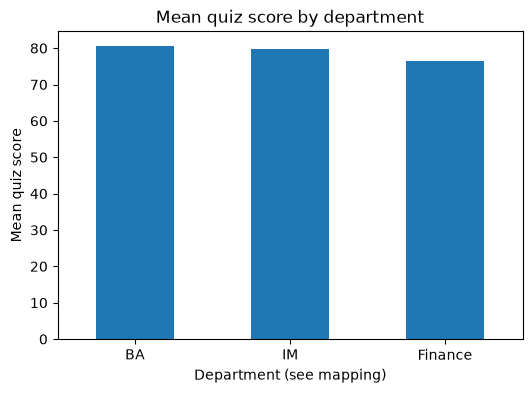

代碼對照： {'資訊管理': 'IM', '企業管理': 'BA', '金融管理': 'Finance'}


In [23]:
# 重建圖表顯示用資料，沒有改動原始 department
english_names = {"資訊管理": "IM", "企業管理": "BA", "金融管理": "Finance"}
means = summary["mean"].copy()
means.index = [english_names[name] for name in means.index]
means.plot(kind="bar", figsize=(6, 4), rot=0)
plt.title("Mean quiz score by department")
plt.xlabel("Department (see mapping)")
plt.ylabel("Mean quiz score")
plt.show()
print("代碼對照：", english_names)


## 📝 學生作業 05-Q2｜AI 查詢與作答：關聯與因果
**任務：**本例不同科系的平均分數不同，能否證明科系造成差異？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請根據「科系隨機生成，成績公式未使用科系」說明組間平均差不能直接推論因果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 05-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：kklc；我是 Python 與資料分析初學者。請根據「科系隨機生成，成績公式未使用科系」說明組間平均差不能直接推論因果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。

- AI 回答重點（請自行整理）：
在「科系是隨機生成、成績公式沒有使用科系」的條件下，你看到「IM、BA、Finance 三組平均分數不同」，只能說「這一份抽樣資料裡，三組平均恰好不同」；不能直接推論「科系造成成績差異」。

- 我的理解與具體例子：
科系及成績分類都是隨機抽樣分組的，而成績的紀錄及平均的算法都和科系無關，所以平均和科系無因果關係。
(例子如下)

In [26]:
import numpy as np
import pandas as pd

np.random.seed(123)

n = 100          # 每次模擬 100 個學生
n_sims = 1000    # 重複模擬 1000 次

diffs = []

for _ in range(n_sims):
    # 1. 隨機生成科系：只用兩個科系，方便看 IM - BA
    dept = np.random.choice(["IM", "BA"], size=n)

# 2. 生成一個跟科系無關的背景變數，例如努力程度
    effort = np.random.normal(10, 2, n)

    # 3. 成績公式：完全沒有使用 dept
    #    score = 基礎分 + 努力程度影響 + 隨機誤差
    score = 50 + 0.8 * effort + np.random.normal(0, 3, n)

    # 4. 做成 DataFrame
    df = pd.DataFrame({
        "dept": dept,
        "score": score
    })

    # 5. 計算兩組平均
    mean_by_dept = df.groupby("dept")["score"].mean()

    # 6. 計算 IM 平均 - BA 平均
    #    如果某次模擬某一組沒有學生，這裡會出錯。
    #    n=100 時這種情況機率很低，但嚴格說仍可用 if 檢查。
    if "IM" in mean_by_dept.index and "BA" in mean_by_dept.index:
        diff = mean_by_dept["IM"] - mean_by_dept["BA"]
        diffs.append(diff)

diffs = np.array(diffs)

print("所有模擬的平均差之平均值：")
print(diffs.mean())

print("平均差的中位數：")
print(np.median(diffs))

print("平均差的 5%、50%、95% 分位數：")
print(np.percentile(diffs, [5, 50, 95]))

所有模擬的平均差之平均值：
0.048049227080566845
平均差的中位數：
0.05281613098112814
平均差的 5%、50%、95% 分位數：
[-1.04259751  0.05281613  1.15904002]


- 查證來源／方式及日期（無法查證請註明）：統計課程教材（隨機化實驗、抽樣變異相關章節）、對照 pandas 官方文件，確認 Series.copy() 會產生獨立副本，修改副本的 index 不會影響原始 summary["mean"]、上面的例子驗證。

- 我檢查或修正 AI 回答的地方：無


## 5.3 解釋差異的限制
**討論：**科系平均不同是否證明科系造成成績差距？不行；本例科系隨機產生、樣本有限，而且有其他學習欄位與隨機誤差。
**學生交付：**列出每組人數、平均與中位數；依實際結果寫一項觀察及一項不能推論的結論。


## 延伸：size 與 count
`size` 包含欄位缺失的資料列；`count` 只數指定欄非缺失的值。科系比較若忽略有效筆數，容易對小組或缺失組作過度解讀。


In [34]:
df = df.reset_index()
print(df.columns.tolist()) 

['index', 'student_id', 'department', 'sleep_hours', 'screen_time_hours', 'study_hours', 'attendance_rate', 'quiz_score']


In [36]:
# 比較每個科系的資料列數與睡眠欄有效數
all_rows = df.groupby("department").size().rename("rows")
valid_sleep = df.groupby("department")["sleep_hours"].count().rename("valid_sleep")
display(pd.concat([all_rows, valid_sleep], axis=1))
assert all_rows.sum() == len(df)


,rows,valid_sleep
department,,
企業管理,21,21
資訊管理,15,14
金融管理,24,23


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

在任務五中，學到了將資料以各個欄位做分組，其中再以department當作index計算平均及中位數的數值，了解到平均值和科系並不存在因果關係，所以不能單憑平均就判斷一個科系的好壞，也了解到缺失值及有效數值的紀錄。
其中遇到的問題是department欄位在輸出的表格中和其他欄為標題是不對齊的，其中原因就是程式將department當為索引欄位而非一般欄位，想要輸出整齊只要加上as_index=False就好，不過要注意如果後續是以department的index抓資料的話，須改回來，不然可能報錯。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。
